In [8]:
import lsst.afw.display as afwDisplay
from lsst.afw.display import Mosaic
from lsst.daf.butler import Butler
from IPython.display import clear_output
from astropy.time import Time
from lsst.daf.butler import Timespan

In [9]:
butler = Butler("/arc/projects/NewHorizons/clean_horizons/BUTLER")
collections = butler.collections.query('*')

In [10]:
dataset_type = "flat"

In [4]:
domeflats = butler.query_dimension_records('exposure', 
                                           where="instrument='HSC' and exposure.observation_type='domeflat' and detector=50", limit=10)

In [11]:
refs = butler.query_datasets(dataset_type, 
                                     collections=collections, 
                                     instrument='HSC', 
                                     find_first=False)

In [12]:
det_to_idx = { refs[i].dataId['detector']:i for i in range(len(refs)) } 

In [13]:
display = afwDisplay.Display(backend='firefly')
display.scale('linear', 'zscale')
display.mtv(butler.get(refs[-1]))

In [ ]:
display = afwDisplay.Display(backend='firefly')
while True:
    det = input("Which patch would you like to show? (Q to Quit)")
    if det == "Q":
        break
    if det == "n":
        idx += 1
    else:
        idx = det_to_idx.get(int(det), 0)
    ref = refs[idx]
    clear_output(wait=True)
    print(f"Loading exposure:{ref.dataId['detector']}")
    exposure = butler.get(ref)
    display.mtv(exposure)
    display.zoom(.3)

Loading exposure:103


In [12]:
len(refs)

103

In [83]:
butler=Butler("/arc/projects/NewHorizons/clean_horizons/BUTLER", writeable=True)

In [7]:
# Inspect flat associations and their validity ranges in a CALIBRATION collection
    print(assoc.ref.dataId, assoc.timespan)



{instrument: 'HSC', detector: 0, physical_filter: 'HSC-R2', band: 'r'} [2021-06-01T00:00:00, 2021-06-01T00:00:37)


In [18]:
dataId = { key: assoc.ref.dataId.mapping[key] for key in assoc.ref.dataId.mapping}

In [104]:
dataIds = []

In [105]:
for assoc in butler.registry.queryDatasetAssociations("bias", 
                                                      collections="HSC/calib"):
    if assoc.ref.dataId['detector']>0:
        dataIds.append(assoc.ref.dataId)


In [108]:
butler.registry.decertify(
    "HSC/calib",
    "bias",
    assoc.timespan,
    dataIds=dataIds,
)

In [30]:
refs = butler.registry.queryDatasetAssociations("flat", 
                                                collections="HSC/calib")

In [31]:
for assoc in refs:
    if assoc.ref.dataId['detector']==50:
        print(assoc)

In [32]:
butler.close()

In [7]:
m = Mosaic()
m.setGutter(5)
m.setBackground(10)
m.setMode("square")                     # the default; other options are "x" or "y"

for idx, bias_img in enumerate(bias_imgs):
    label = f"Detector: {bias_refs[idx].dataId['detector']:03d}"
    m.append(bias_img.image, label)

mosaic = m.makeMosaic()
display = afwDisplay.getDisplay()
display.mtv(mosaic)                     # display it
m.drawLabels(display=display) # label the panels

In [25]:
d = butler.query_datasets('cpBiasDetCore_biasStdByDate_GridPlot', collections='HSC/cp')

In [2]:
collections='NH/singleVisitImages/20210905'
collections="NH/singleVisitImages/20210905/20261124T153023Z"
butler = Butler('/arc/projects/NewHorizons/clean_horizons/BUTLER', collections=collections)

In [3]:
cat_refs = butler.query_datasets('sso_injection_catalog', where="instrument='HSC' and visit=263636")

In [15]:
cat = butler.get(cat_refs[0])

In [16]:
from matplotlib import pyplot

In [4]:
butler.getURI(cat_refs[0])

ResourcePath("file:///arc/projects/NewHorizons/clean_horizons/BUTLER/NH/singleVisitImages/20210905/20261124T153023Z/sso_injection_catalog/20210905/r/HSC-R2/263636/sso_injection_catalog_HSC_r_HSC-R2_263636_1_12_NH_singleVisitImages_20210905_20261124T153023Z.parq")

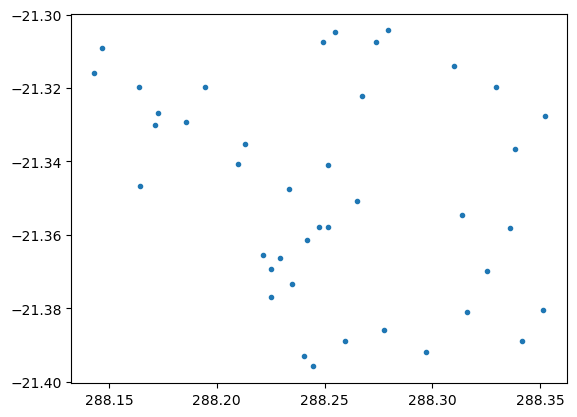

In [17]:
pyplot.plot(cat['ra'], cat['dec'], '.')

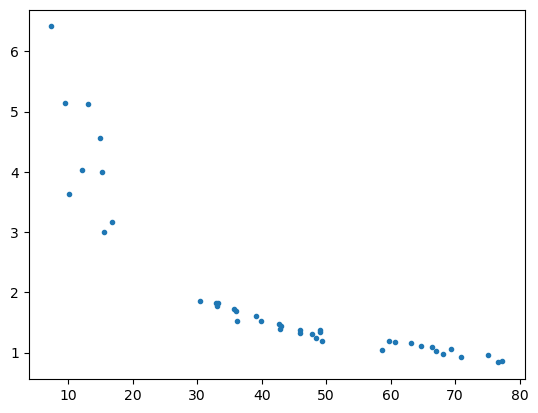

In [27]:
pyplot.plot(cat['delta'], cat['rate'], '.')

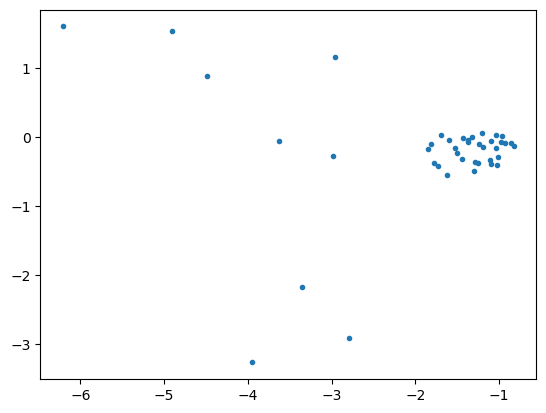

In [28]:
pyplot.plot(cat['dra'], cat['ddec'], '.')

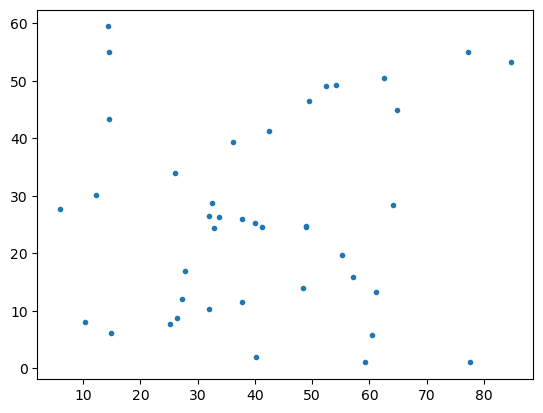

In [37]:
pyplot.plot(cat['a'], cat['inc'].to('degree'), '.')

In [7]:
import os
import lsst.geom as geom
from lsst.daf.butler import Butler

# 1. Connect to your project Butler and verify the registry & dataset
butler = Butler("/arc/projects/NewHorizons/clean_horizons/BUTLER/", collections="skymaps")

skymap_records = list(butler.registry.queryDimensionRecords("skymap"))
print("Registered skymap records:", skymap_records)

skymap = butler.get("skyMap", skymap="lsst_cells_v2")
print(f"Loaded SkyMap: {type(skymap).__name__} with {len(skymap)} tracts")

# 2. Define the New Horizons Subaru HSC search field center (RA=289.1 deg, Dec=-20.36 deg)
field_center = geom.SpherePoint(289.1 * geom.degrees, -20.36 * geom.degrees)

# Find all tracts overlapping a 1.5-degree radius (~1 Subaru HSC FoV) around the field center
search_radius = 1.5 * geom.degrees
nearby_tracts = skymap.findTractIdArray(
    [field_center.getRa().asRadians()],
    [field_center.getDec().asRadians()],
    degrees=False
)

# Better yet, query all tracts whose centers fall within ~2.5 degrees of the field center
print("\n--- Tracts & Patch Geometry Near Field Center ---")
for tract_info in skymap:
    sep = tract_info.getCtrCoord().separation(field_center)
    if sep < 2.5 * geom.degrees:
        wcs = tract_info.getWcs()
        pixel_scale = wcs.getPixelScale().asArcseconds()
        
        # Inspect patch (0, 0) as representative of the tract's 10x10 patch grid
        patch_info = tract_info.getPatchInfo((0, 0))
        inner_bbox = patch_info.getInnerBBox()
        outer_bbox = patch_info.getOuterBBox()
        
        inner_arcmin = (inner_bbox.getWidth() * pixel_scale / 60.0, inner_bbox.getHeight() * pixel_scale / 60.0)
        outer_arcmin = (outer_bbox.getWidth() * pixel_scale / 60.0, outer_bbox.getHeight() * pixel_scale / 60.0)
        
        # Count how many patches in this tract fall within the 0.75 deg HSC FoV radius
        patches_in_fov = sum(
            1 for p in tract_info
            if wcs.pixelToSky(p.getInnerBBox().getCenter()).separation(field_center) < 0.75 * geom.degrees
        )
        
        print(
            f"Tract {tract_info.getId():5d} | Sep: {sep.asDegrees():.2f}° | "
            f"Scale: {pixel_scale:.3f}\"/px | "
            f"Inner Patch: {inner_bbox.getWidth()}x{inner_bbox.getHeight()} px ({inner_arcmin[0]:.2f}'x{inner_arcmin[1]:.2f}') | "
            f"Outer Patch: {outer_bbox.getWidth()}x{outer_bbox.getHeight()} px ({outer_arcmin[0]:.2f}'x{outer_arcmin[1]:.2f}') | "
            f"Patches in 1.5° FoV: {patches_in_fov}/100"
        )


Registered skymap records: [skymap.RecordClass(name='lsst_cells_v2', hash=b'\xa5\xf1\x1eV\x15\x05\xdck$\xec\x8fN\xf5G\xbcY.\x82\x99\xda', tract_max=18938, patch_nx_max=10, patch_ny_max=10)]
Loaded SkyMap: RingsSkyMap with 18938 tracts

--- Tracts & Patch Geometry Near Field Center ---
Tract  6094 | Sep: 2.27° | Scale: 0.200"/px | Inner Patch: 3000x3000 px (10.00'x10.00') | Outer Patch: 3300x3300 px (11.00'x11.00') | Patches in 1.5° FoV: 0/100
Tract  6095 | Sep: 1.29° | Scale: 0.200"/px | Inner Patch: 3000x3000 px (10.00'x10.00') | Outer Patch: 3300x3300 px (11.00'x11.00') | Patches in 1.5° FoV: 11/100
Tract  6096 | Sep: 1.60° | Scale: 0.200"/px | Inner Patch: 3000x3000 px (10.00'x10.00') | Outer Patch: 3300x3300 px (11.00'x11.00') | Patches in 1.5° FoV: 3/100
Tract  6323 | Sep: 1.36° | Scale: 0.200"/px | Inner Patch: 3000x3000 px (10.00'x10.00') | Outer Patch: 3300x3300 px (11.00'x11.00') | Patches in 1.5° FoV: 7/100
Tract  6324 | Sep: 0.31° | Scale: 0.200"/px | Inner Patch: 3000x3000 